## Function Transformer 

In [2]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('train.csv', usecols = ['Age', 'Fare', 'Survived'])

In [4]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [6]:
df['Age'].fillna(df['Age'].mean(), inplace= True)

/var/folders/2s/95wdsz_j2jn5xl0d74jbk2fw0000gn/T/ipykernel_14543/1444409324.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace= True)


In [7]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [8]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [9]:
x = df.iloc[:, 1:3]
y = df.iloc[:, 0]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

Text(0.5, 1.0, 'Age QQ plot')

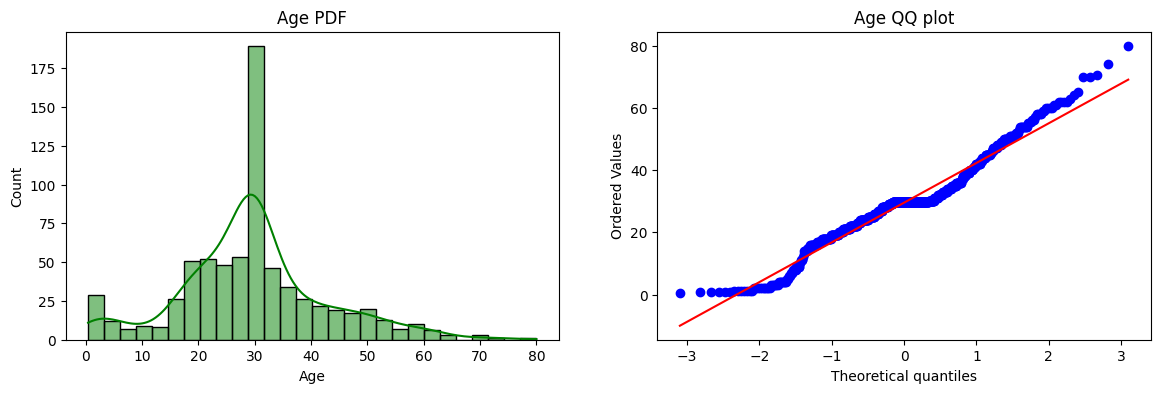

In [11]:
# Age Plot
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train['Age'], kde=True, color='green')
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Age'], dist='norm', plot=plt)
plt.title('Age QQ plot')


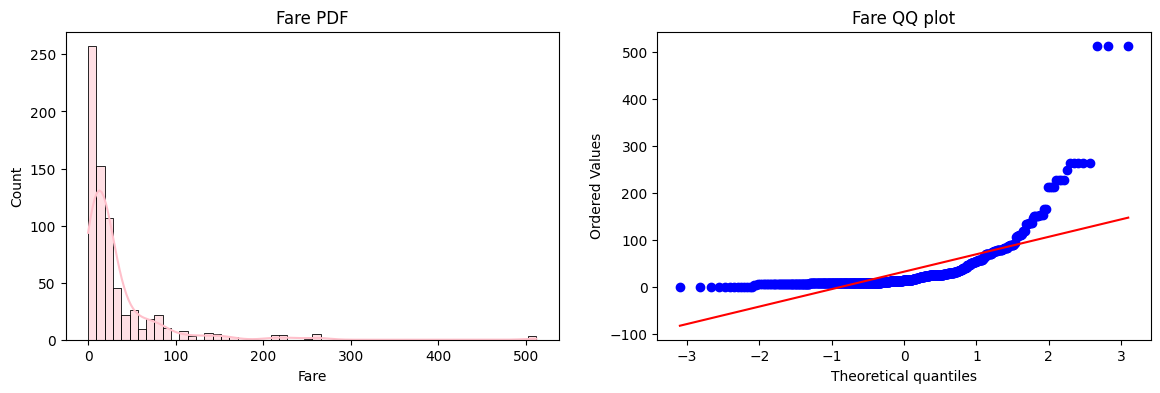

In [12]:
# FARE columnplt
plt.figure(figsize=(14,4)) # It controls the width and height of your plot
plt.subplot(121) # 1, 2, 1 (rows, columns, position)
sns.histplot(x_train['Fare'], kde= True, color= 'pink')
plt.title('Fare PDF') 

plt.subplot(122)
stats.probplot(x_train['Fare'], dist='norm', plot=plt)
plt.title('Fare QQ plot')

plt.show()

In [13]:
# Accuracy Before Function Transformer

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred = clf.predict(x_test)
y_pred1 = clf2.predict(x_test)

print('Accuracy LR :', accuracy_score(y_test,y_pred))
print('Accuracy DT :', accuracy_score(y_test,y_pred1))

Accuracy LR : 0.6480446927374302
Accuracy DT : 0.6871508379888268


In [14]:
# Accuracy after Function Transformer 
trf = FunctionTransformer(func=np.log1p)


In [15]:
x_train_transformed = trf.fit_transform(x_train)
x_test_transformed = trf.transform(x_test)

In [16]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)

y_pred = clf.predict(x_test_transformed)
y_pred1 = clf2.predict(x_test_transformed)

print('Accuracy of LR:', accuracy_score(y_test,y_pred))
print('Accuracy of DT:', accuracy_score(y_test,y_pred))





Accuracy of LR: 0.6815642458100558
Accuracy of DT: 0.6815642458100558


In [18]:
x_transformed = trf.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,x_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,x_transformed,y,scoring='accuracy',cv=10)))



LR 0.678027465667915
DT 0.6588639200998753


In [19]:
# CUSTOM
def apply_func(transformer):
    x = df.iloc[:,1:3]
    y = df.iloc[:,0]

    trf = ColumnTransformer([('log', FunctionTransformer(transformer),['Fare'])],remainder='passthrough')

    x_train = trf.fit_transform(x)

    clf = LogisticRegression()

    print('Accuracy:', np.mean(cross_val_score(clf, x_train,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(x['Fare'], dist='norm',plot=plt)
    plt.title("Fare before Transform")

    plt.figure(figsize=(14,4))

    plt.subplot(122)
    stats.probplot(x_train[:,0], dist='norm', plot=plt)
    plt.title("Fare after Transform")
    



Accuracy: 0.6195131086142323


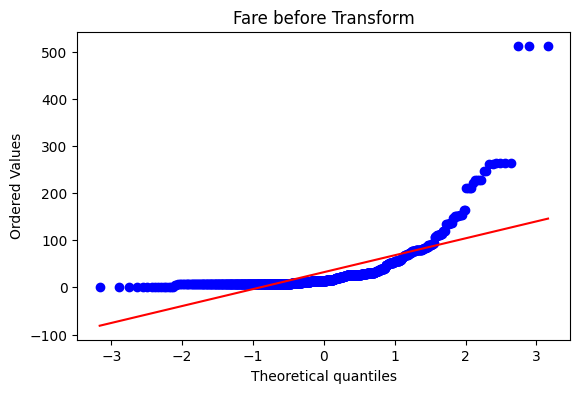

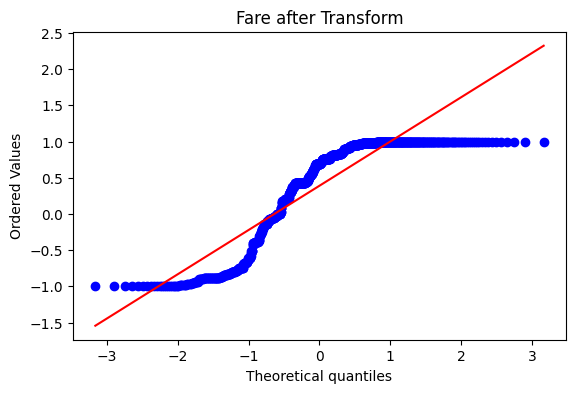

In [18]:
apply_func(np.sin)